# 03 — Auto-encodeurs & détection d'anomalies

**Projet DiagnoCulture** — diagnostic des maladies de la tomate (10 classes, PlantVillage).

Cette partie change de paradigme : on ne **classe** plus les maladies, on apprend à **reconstruire** des feuilles **saines uniquement**. Une feuille malade, jamais vue à l'entraînement, se reconstruit mal → l'**erreur de reconstruction** `‖x − x̂‖²` sert de **score d'anomalie** (principe non supervisé du chapitre 3).

**Plan.** (1) Setup · (2) Données (saines pour l'entraînement, mixte pour l'évaluation) · (3) Auto-encodeur convolutif · (4) Étude de la dimension latente *k* · (5) Variante débruiteuse · (6) Détection d'anomalies (seuil, AUROC, rappel) · (7) Analyse des échecs · (8) Conclusion.

> Règle d'or : l'AE s'entraîne **sur le sain seul**. Le **seuil** se fixe sur la **validation**, et le **test** ne sert qu'**une seule fois**.

*Références : chapitre 3 du cours (auto-encodeurs, espace latent, détection d'anomalies) ; conventions reprises du notebook `02_transfer_learning`.*

## 1. Setup

**Tous les imports sont regroupés ci-dessous.** Nouveauté par rapport au `02` : `roc_auc_score` (métrique de détection d'anomalies, étape 4).

In [1]:
# =========================================================
#  IMPORTS (tous regroupés ici)
# =========================================================
!pip install -q torchinfo

import os, json, copy, time, random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score        # <-- nouveau (détection d'anomalies, étape 4)
from torchinfo import summary

import kagglehub
from google.colab import drive

**Reproductibilité + device.** On fixe les graines (Python, NumPy, PyTorch, cuDNN déterministe) et on sélectionne le GPU.

In [2]:
# --- Reproductibilité + device (identique au 02) ---
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)   # attendu : cuda

device: cuda


**Montage de Drive + dataset + découpage figé.** Le cache kagglehub est temporaire ; seul Drive (`Project_clean`) persiste d'une session à l'autre. On recharge le `split.csv` figé de la Partie 1 → résultats directement comparables.

In [3]:
# --- Drive + dataset + split figé (identique au 02) ---
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")       # split.csv
MODELS  = os.path.join(ROOT, "models")     # .pt
RESULTS = os.path.join(ROOT, "results")    # figures .png + config .json
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)

base = kagglehub.dataset_download("emmarex/plantdisease")

DATA_ROOT = None
for r, d, _ in os.walk(base):
    if any(x.startswith("Tomato") for x in d):
        DATA_ROOT = r
        break

classes = sorted(c for c in os.listdir(DATA_ROOT) if c.startswith("Tomato"))
clean_data = pd.read_csv(os.path.join(DATA, "split.csv"))
print("DATA_ROOT =", DATA_ROOT)
print(clean_data["split"].value_counts())

Mounted at /content/drive
Using Colab cache for faster access to the 'plantdisease' dataset.
DATA_ROOT = /kaggle/input/plantdisease/PlantVillage
split
train    11197
test      2400
val       2400
Name: count, dtype: int64


**Configuration de la Partie 3.** Choix imposés par l'annexe et propres à l'auto-encodeur :
- `IMG_AE = 64` : résolution imposée pour les auto-encodeurs (budget de calcul).
- `LATENT_DIMS = [16, 64, 256]` : les trois tailles de goulot à comparer (étape 2).
- `HEALTHY_CLASS = "Tomato_healthy"` : la **seule** classe « normale », la seule vue à l'entraînement.

In [4]:
# --- Config Partie 3 (auto-encodeur) ---
IMG_AE        = 64                 # résolution imposée pour les AE (annexe)
BATCH         = 128
EPOCHS        = 60
PATIENCE      = 8
LATENT_DIMS   = [16, 64, 256]      # étude de k (étape 2)
HEALTHY_CLASS = "Tomato_healthy"   # la seule classe "normale"

## 2. Données

Particularité de cette partie : il faut **4 DataLoaders**, car l'entraînement et l'évaluation ne portent pas sur les mêmes données.

| loader | contenu | rôle |
|---|---|---|
| `ae_train` | saines train (1109), **augmentées** | entraîner l'AE |
| `ae_val` | saines val (238) | early-stopping (reconstruction du sain) |
| `val_eval` | **tout** val (2400), label binaire | histogrammes + fixer le **seuil** |
| `test_eval` | **tout** test (2400), label binaire | évaluation finale (AUROC, rappel, fausses alarmes) |

**Deux différences de fond avec le `02`.** (1) **Pas de `Normalize`** : l'AE doit reconstruire des pixels dans `[0,1]` (d'où la sigmoïde finale) ; on garde donc seulement `ToTensor()`. (2) Le `Dataset` renvoie un **label binaire** `y` (0 = saine, 1 = anomalie) : ignoré pour l'entraînement (auto-supervisé), utilisé seulement pour la détection.

In [5]:
# --- Transforms : PAS de Normalize (on reconstruit des pixels dans [0,1]) ---
train_transform = transforms.Compose([
    transforms.Resize((IMG_AE, IMG_AE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),          # PIL -> tenseur (C,H,W), pixels dans [0,1]
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_AE, IMG_AE)),
    transforms.ToTensor(),
])

# --- Dataset : renvoie (image, label_anomalie) ---
class LeafAE(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")
        x = self.transform(img)
        y = 0 if row["label"] == HEALTHY_CLASS else 1   # 0 = saine, 1 = anomalie
        return x, y

**Sous-ensembles et DataLoaders.** `train_df`/`val_df` partent des saines ; `val_all`/`test_all` gardent **toutes** les classes. `shuffle=False` sur val/test : l'ordre des erreurs correspondra à l'ordre des lignes du DataFrame → indispensable pour relier chaque erreur à **sa maladie** (étape 5).

In [6]:
# --- Sous-ensembles ---
heal     = clean_data[clean_data["label"] == HEALTHY_CLASS]
train_df = heal[heal["split"] == "train"]          # saines train
val_df   = heal[heal["split"] == "val"]            # saines val
val_all  = clean_data[clean_data["split"] == "val"]    # tout val (mixte)
test_all = clean_data[clean_data["split"] == "test"]   # tout test (mixte)

# --- 4 DataLoaders ---
ae_train  = DataLoader(LeafAE(train_df, train_transform), BATCH, shuffle=True,  num_workers=2, pin_memory=True)
ae_val    = DataLoader(LeafAE(val_df,   eval_transform),  BATCH, shuffle=False, num_workers=2, pin_memory=True)
val_eval  = DataLoader(LeafAE(val_all,  eval_transform),  BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_eval = DataLoader(LeafAE(test_all, eval_transform),  BATCH, shuffle=False, num_workers=2, pin_memory=True)

# --- Vérifs ---
xb, yb = next(iter(ae_train))
print("batch AE :", xb.shape, "| min/max pixels :", xb.min().item(), xb.max().item())  # [128,3,64,64], 0..1
print("saines train/val :", len(train_df), len(val_df))
print("val mixte  (0/1) :", (val_all['label']==HEALTHY_CLASS).sum(),  (val_all['label']!=HEALTHY_CLASS).sum())
print("test mixte (0/1) :", (test_all['label']==HEALTHY_CLASS).sum(), (test_all['label']!=HEALTHY_CLASS).sum())

batch AE : torch.Size([128, 3, 64, 64]) | min/max pixels : 0.0 0.9058823585510254
saines train/val : 1109 238
val mixte  (0/1) : 238 2162
test mixte (0/1) : 238 2162


**Résultat.** Un batch sort en `[128, 3, 64, 64]`, pixels bien dans `[0,1]`. Effectifs conformes : **1109 / 238** saines (train/val), et **238 saines / 2162 malades** en validation comme en test. Les données sont prêtes.

## 3. L'auto-encodeur convolutif

**Vocabulaire du cours.** encodeur **f** : `x → z = f(x)`, avec un **code latent** `z ∈ ℝ^k` de dimension **k ≪ n** (le goulot d'étranglement). Décodeur **g** : `z → x̂ = g(z)`. On minimise la **MSE** `‖x − x̂‖²`.

**Encodeur** — 3 convolutions stride-2 (la taille est divisée par 2 à chaque fois) :

| opération | sortie (C×H×W) |
|---|---|
| entrée x | 3 × 64 × 64 |
| Conv2d(3→16, k=4, s=2, p=1) + ReLU | 16 × 32 × 32 |
| Conv2d(16→32, k=4, s=2, p=1) + ReLU | 32 × 16 × 16 |
| Conv2d(32→64, k=4, s=2, p=1) + ReLU | 64 × 8 × 8 |
| Flatten + Linear(64·8·8 → k) | **z ∈ ℝ^k** |

**Décodeur** — le miroir, avec `ConvTranspose2d` (qui **double** la taille), et une **sigmoïde** finale pour borner x̂ dans `[0,1]`.

Le constructeur prend **`k`** en paramètre : c'est lui qu'on fera varier (16/64/256). Les méthodes `encode`/`decode` sont séparées — `encode` resservira en Partie 4 pour récupérer le code latent.

In [7]:
class ConvAutoencoder(nn.Module):
    def __init__(self, k):
        super().__init__()
        # encodeur f : 3 convs stride-2 (64 -> 8)
        self.encodeur = nn.Sequential(
            nn.Conv2d(3,  16, kernel_size=4, stride=2, padding=1), nn.ReLU(),  # 64 -> 32
            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),  # 32 -> 16
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),  # 16 -> 8
        )
        self.fc_enc = nn.Linear(64 * 8 * 8, k)   # -> code z
        self.fc_dec = nn.Linear(k, 64 * 8 * 8)   # z -> features

        # décodeur g : 3 ConvTranspose stride-2 (8 -> 64), sigmoïde finale
        self.decodeur = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),  # 8  -> 16
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1), nn.ReLU(),  # 16 -> 32
            nn.ConvTranspose2d(16, 3,  kernel_size=4, stride=2, padding=1), nn.Sigmoid(),# 32 -> 64
        )

    def encode(self, x):                 # renvoie z (servira en Partie 4)
        h = self.encodeur(x)
        h = torch.flatten(h, 1)          # (N,64,8,8) -> (N, 4096)
        return self.fc_enc(h)

    def decode(self, z):                 # renvoie x̂
        h = self.fc_dec(z)
        h = h.view(-1, 64, 8, 8)         # (N,4096) -> (N,64,8,8)
        return self.decodeur(h)

    def forward(self, x):
        return self.decode(self.encode(x))

**Vérification des dimensions** (passage à blanc + `torchinfo`).

In [8]:
m = ConvAutoencoder(k=64).to(device)
x = torch.randn(8, 3, 64, 64).to(device)
print(m(x).shape)          # torch.Size([8, 3, 64, 64])
print(m.encode(x).shape)   # torch.Size([8, 64])
summary(m, input_size=(1, 3, 64, 64))

torch.Size([8, 3, 64, 64])
torch.Size([8, 64])


Layer (type:depth-idx)                   Output Shape              Param #
ConvAutoencoder                          [1, 3, 64, 64]            --
├─Sequential: 1-1                        [1, 64, 8, 8]             --
│    └─Conv2d: 2-1                       [1, 16, 32, 32]           784
│    └─ReLU: 2-2                         [1, 16, 32, 32]           --
│    └─Conv2d: 2-3                       [1, 32, 16, 16]           8,224
│    └─ReLU: 2-4                         [1, 32, 16, 16]           --
│    └─Conv2d: 2-5                       [1, 64, 8, 8]             32,832
│    └─ReLU: 2-6                         [1, 64, 8, 8]             --
├─Linear: 1-2                            [1, 64]                   262,208
├─Linear: 1-3                            [1, 4096]                 266,240
├─Sequential: 1-4                        [1, 3, 64, 64]            --
│    └─ConvTranspose2d: 2-7              [1, 32, 16, 16]           32,800
│    └─ReLU: 2-8                         [1, 32, 16, 16]       

**Résultat.** La reconstruction ressort bien en `[8, 3, 64, 64]` et le code latent en `[8, 64]`. Pour k=64 : **~612 k paramètres**, dont **~528 k concentrés dans les deux couches `Linear`** du goulot (`4096 ↔ k`) — les convolutions, elles, sont très légères.

## 4. Entraînement + étude de la dimension latente *k*

**Fonction d'entraînement.** Même esprit que le `train_model` du `02` (boucle train/val, early-stopping, sauvegarde du meilleur sur Drive), adaptée à l'AE : perte **MSE**, et la **cible est l'image elle-même** (`criterion(out, x)`), pas un label. Le paramètre `denoising` est déjà prévu ici (il servira tel quel en partie 5).

In [9]:
def train_ae(k, denoising=False, noise_std=0.3, epochs=EPOCHS, patience=PATIENCE, tag=None):
    set_seed(42)
    model = ConvAutoencoder(k).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    hist = {"train": [], "val": []}
    best_val, best_w, wait = float("inf"), copy.deepcopy(model.state_dict()), 0

    for ep in range(1, epochs + 1):
        # --- entraînement ---
        model.train(); run, n = 0.0, 0
        for x, _ in ae_train:                       # on ignore le label
            x = x.to(device)
            inp = (x + noise_std * torch.randn_like(x)).clamp(0, 1) if denoising else x
            optimizer.zero_grad()
            out = model(inp)
            loss = criterion(out, x)                # cible = image PROPRE
            loss.backward(); optimizer.step()
            run += loss.item() * x.size(0); n += x.size(0)
        tr = run / n

        # --- validation (reconstruction du sain) ---
        model.eval(); vrun, vn = 0.0, 0
        with torch.no_grad():
            for x, _ in ae_val:
                x = x.to(device)
                inp = (x + noise_std * torch.randn_like(x)).clamp(0, 1) if denoising else x
                vrun += criterion(model(inp), x).item() * x.size(0); vn += x.size(0)
        vl = vrun / vn

        hist["train"].append(tr); hist["val"].append(vl)
        print(f"[{tag}] ep {ep:2d} | train {tr:.5f} | val {vl:.5f}")

        if vl < best_val:
            best_val, best_w, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                print(f"[{tag}] early-stop ep {ep}"); break

    model.load_state_dict(best_w)
    if tag:
        torch.save(best_w, os.path.join(MODELS, f"ae_{tag}_best.pt"))
    hist["best_val"] = best_val
    return model, hist

**Étude de k.** On entraîne un AE **simple** (sans bruit) pour chaque `k ∈ {16, 64, 256}` et on compare la MSE de validation.

In [10]:
# --- Étude de k : on entraîne un AE simple pour chaque k ---
ae_models, ae_hist = {}, {}
for k in LATENT_DIMS:                       # [16, 64, 256]
    tag = f"k{k}"
    m, h = train_ae(k, denoising=False, tag=tag)
    ae_models[tag], ae_hist[tag] = m, h
    print(f"  -> k={k:3d} | best val MSE = {h['best_val']:.5f}\n")

[k16] ep  1 | train 0.03248 | val 0.01932
[k16] ep  2 | train 0.02951 | val 0.01846
[k16] ep  3 | train 0.02666 | val 0.01860
[k16] ep  4 | train 0.02473 | val 0.01871
[k16] ep  5 | train 0.02338 | val 0.01922
[k16] ep  6 | train 0.02258 | val 0.01934
[k16] ep  7 | train 0.02176 | val 0.01791
[k16] ep  8 | train 0.02096 | val 0.01716
[k16] ep  9 | train 0.01975 | val 0.01508
[k16] ep 10 | train 0.01740 | val 0.01384
[k16] ep 11 | train 0.01574 | val 0.01318
[k16] ep 12 | train 0.01479 | val 0.01214
[k16] ep 13 | train 0.01417 | val 0.01170
[k16] ep 14 | train 0.01358 | val 0.01144
[k16] ep 15 | train 0.01297 | val 0.01103
[k16] ep 16 | train 0.01246 | val 0.01048
[k16] ep 17 | train 0.01188 | val 0.01016
[k16] ep 18 | train 0.01155 | val 0.00989
[k16] ep 19 | train 0.01145 | val 0.00971
[k16] ep 20 | train 0.01105 | val 0.00962
[k16] ep 21 | train 0.01076 | val 0.00950
[k16] ep 22 | train 0.01051 | val 0.00929
[k16] ep 23 | train 0.01034 | val 0.00912
[k16] ep 24 | train 0.01013 | val 

**Résultat.**

| k | best val MSE | compression (12288 → k) |
|---|---|---|
| 16 | 0,00769 | ×768 |
| 64 | 0,00544 | ×192 |
| 256 | **0,00470** | ×48 |

**Interprétation.** La MSE **baisse quand k augmente** : plus le goulot est large, plus l'AE a de capacité pour reconstruire fidèlement (slides 9 et 11 du cours). Les trois n'ont pas déclenché l'early-stop (60 epochs pleins). ⚠️ Mais attention : la plus petite MSE n'est **pas** forcément le meilleur **détecteur d'anomalies** — un AE trop performant reconstruit *aussi* bien les malades. On tranchera donc le choix de k **par l'AUROC** (étape 6), pas par la MSE.

**Reconstructions visuelles.** On compare, pour quelques feuilles saines de validation, l'original et la reconstruction de chaque AE.

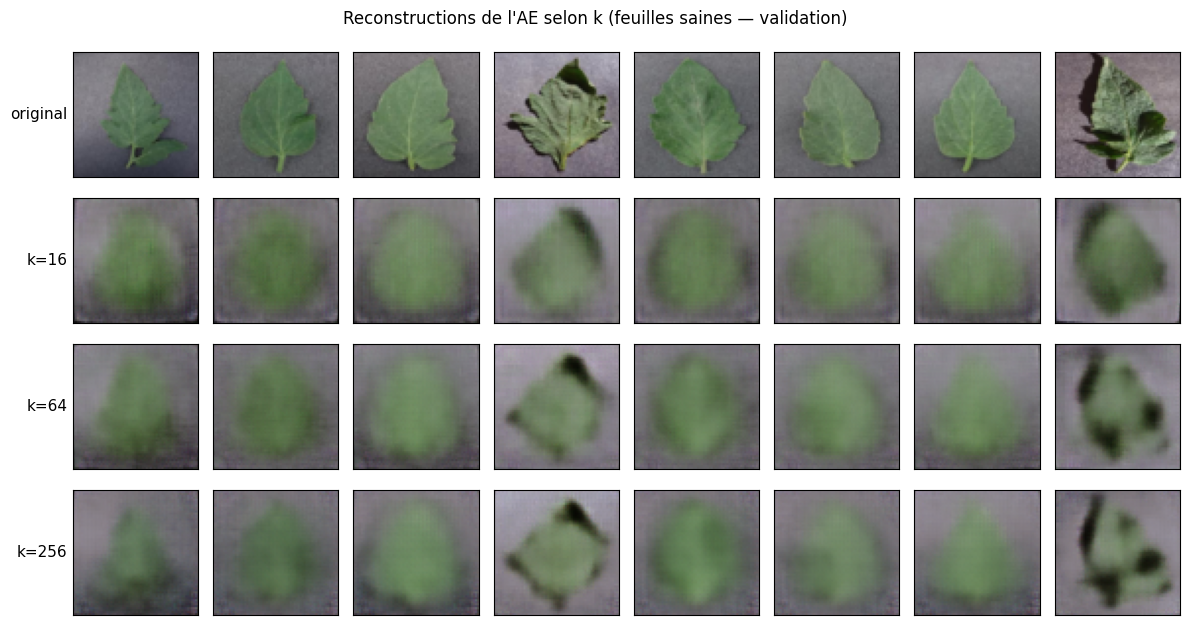

In [11]:
# 8 feuilles saines de validation
imgs, _ = next(iter(ae_val))
imgs = imgs[:8].to(device)

rows = ["original"] + [f"k={k}" for k in LATENT_DIMS]
fig, axes = plt.subplots(len(rows), 8, figsize=(12, 1.6 * len(rows)))

# ligne 0 : images d'origine
for j in range(8):
    axes[0, j].imshow(imgs[j].cpu().permute(1, 2, 0))     # (C,H,W) -> (H,W,C) pour imshow

# lignes suivantes : reconstruction de chaque AE
for i, k in enumerate(LATENT_DIMS, start=1):
    model = ae_models[f"k{k}"].eval()
    with torch.no_grad():
        rec = model(imgs)
    for j in range(8):
        axes[i, j].imshow(rec[j].cpu().permute(1, 2, 0))

# étiquettes de lignes + on enlève les graduations
for i, name in enumerate(rows):
    axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Reconstructions de l'AE selon k (feuilles saines — validation)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "ae_reconstructions_k.png"), dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** Les reconstructions sont **reconnaissables mais floues** : bonne forme et bonne couleur, mais détails fins (nervures, bords dentés) perdus — effet attendu à 64×64, renforcé par la MSE qui favorise une sortie « moyennée ». En descendant `k=16 → 64 → 256`, l'image devient un peu plus nette, mais l'écart reste **subtil à l'œil** alors qu'il est net en MSE.

## 5. Variante débruiteuse (*denoising autoencoder*)

**Principe (slide 16).** On **bruite l'entrée** `x̃ = x + bruit gaussien`, mais la **cible reste l'image propre** `x` : `L = ‖x − g(f(x̃))‖²`. Le réseau ne peut plus recopier l'entrée → il doit apprendre la **structure sous-jacente** d'une feuille saine, ce qui donne des représentations plus robustes. On compare à k fixé (k=64).

In [12]:
K_DN = 64
ae_dn, hist_dn = train_ae(K_DN, denoising=True, noise_std=0.1, tag=f"k{K_DN}_dn")
print("débruiteur (k=64) best val MSE :", round(hist_dn["best_val"], 5))

[k64_dn] ep  1 | train 0.03106 | val 0.01703
[k64_dn] ep  2 | train 0.02720 | val 0.01780
[k64_dn] ep  3 | train 0.02477 | val 0.01985
[k64_dn] ep  4 | train 0.02337 | val 0.01873
[k64_dn] ep  5 | train 0.02239 | val 0.02026
[k64_dn] ep  6 | train 0.02171 | val 0.01840
[k64_dn] ep  7 | train 0.02096 | val 0.01602
[k64_dn] ep  8 | train 0.01996 | val 0.01378
[k64_dn] ep  9 | train 0.01794 | val 0.01325
[k64_dn] ep 10 | train 0.01583 | val 0.01224
[k64_dn] ep 11 | train 0.01434 | val 0.01130
[k64_dn] ep 12 | train 0.01310 | val 0.01048
[k64_dn] ep 13 | train 0.01223 | val 0.00977
[k64_dn] ep 14 | train 0.01166 | val 0.00945
[k64_dn] ep 15 | train 0.01116 | val 0.00926
[k64_dn] ep 16 | train 0.01064 | val 0.00915
[k64_dn] ep 17 | train 0.01027 | val 0.00866
[k64_dn] ep 18 | train 0.00987 | val 0.00845
[k64_dn] ep 19 | train 0.01016 | val 0.00887
[k64_dn] ep 20 | train 0.00994 | val 0.00846
[k64_dn] ep 21 | train 0.00950 | val 0.00807
[k64_dn] ep 22 | train 0.00914 | val 0.00790
[k64_dn] e

**⚠️ Enseignement de debug (à garder pour la soutenance).** Un premier essai à `noise_std=0.3` **détruisait** l'image (entrée ≈ pur bruit) : le réseau sortait une feuille « moyenne » uniforme et l'early-stop tombait dès l'epoch 9 — modèle inutile. Corrigé à **`noise_std=0.1`** (bruit qui dégrade sans détruire) : l'entraînement se déroule normalement, best val MSE **0,00551** (≈ l'AE simple k=64). → Le **niveau de bruit est un hyperparamètre critique** du débruiteur.

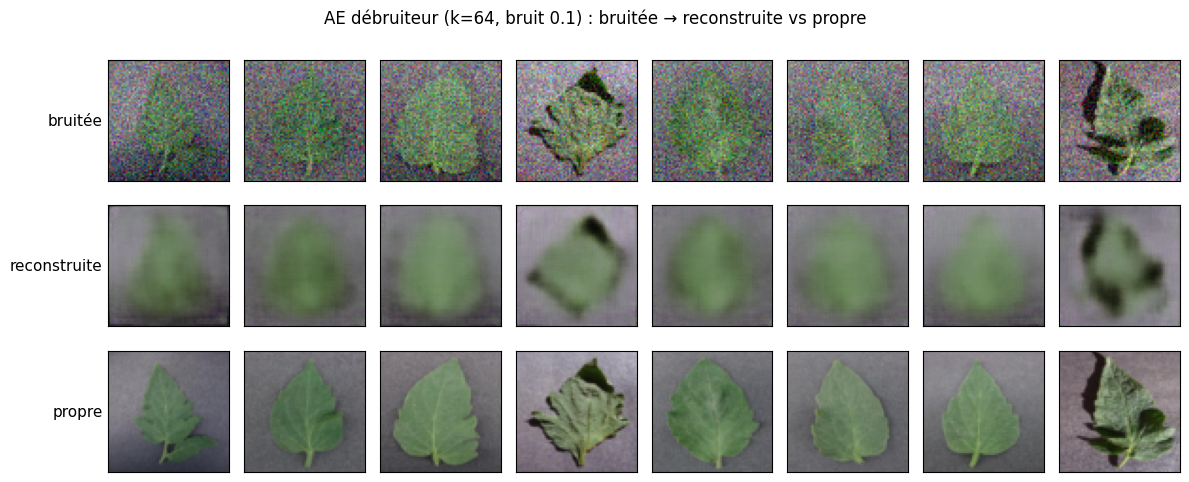

In [13]:
imgs, _ = next(iter(ae_val))
imgs  = imgs[:8].to(device)
noisy = (imgs + 0.1 * torch.randn_like(imgs)).clamp(0, 1)   # 0.1, cohérent avec l'entraînement

ae_dn.eval()
with torch.no_grad():
    rec = ae_dn(noisy)

lignes = {"bruitée": noisy, "reconstruite": rec, "propre": imgs}
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for i, (name, t) in enumerate(lignes.items()):
    for j in range(8):
        axes[i, j].imshow(t[j].cpu().permute(1, 2, 0))
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
    axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11)
plt.suptitle("AE débruiteur (k=64, bruit 0.1) : bruitée → reconstruite vs propre")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "ae_denoising.png"), dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** La ligne « bruitée » est granuleuse, la ligne « reconstruite » retrouve une **vraie feuille propre** proche de la cible : le bruit est bien filtré. Le débruitage fonctionne, et on verra à l'étape 6 qu'il est aussi le **meilleur détecteur**.

## 6. Détection d'anomalies

On calcule l'**erreur de reconstruction par image** `‖x − x̂‖²` (entrée **propre** : on score de vraies images). On s'en sert d'abord pour **choisir le meilleur AE par l'AUROC sur la validation** — et non par la MSE, pour éviter le piège « reconstruction trop bonne ».

In [14]:
@torch.no_grad()
def recon_errors(model, loader):
    """Erreur MSE par image + label (0=saine, 1=anomalie). Entrée PROPRE (on score de vraies images)."""
    model.eval()
    errs, labels = [], []
    for x, y in loader:
        x = x.to(device)
        out = model(x)
        e = ((out - x) ** 2).mean(dim=(1, 2, 3))     # 1 erreur scalaire par image
        errs.append(e.cpu()); labels.append(y)
    return torch.cat(errs).numpy(), torch.cat(labels).numpy()

# --- Sélection du meilleur AE par AUROC sur la VALIDATION ---
candidates = {
    "k16":    ae_models["k16"],
    "k64":    ae_models["k64"],
    "k256":   ae_models["k256"],
    "k64_dn": ae_dn,
}

rows = []
for name, model in candidates.items():
    err_v, y_v = recon_errors(model, val_eval)       # tout val (mixte)
    rows.append({
        "modele":        name,
        "val_AUROC":     round(roc_auc_score(y_v, err_v), 4),
        "MSE_saines":    round(err_v[y_v == 0].mean(), 5),
        "MSE_malades":   round(err_v[y_v == 1].mean(), 5),
    })

sel = pd.DataFrame(rows).sort_values("val_AUROC", ascending=False).reset_index(drop=True)
sel

,modele,val_AUROC,MSE_saines,MSE_malades
0,k64_dn,0.6462,0.00574,0.00828
1,k16,0.6461,0.00769,0.01139
2,k64,0.6387,0.00544,0.00783
3,k256,0.6278,0.00470,0.00655


**Résultat.**

| modèle | val_AUROC | MSE saines | MSE malades | écart |
|---|---|---|---|---|
| **k64_dn** | **0,646** | 0,00574 | 0,00828 | ×1,44 |
| k16 | 0,646 | 0,00769 | 0,01139 | ×1,48 |
| k64 | 0,639 | 0,00544 | 0,00783 | ×1,44 |
| k256 | 0,628 | 0,00470 | 0,00655 | ×1,39 |

**Interprétation.** Résultat clé : **« reconstruction trop bonne » démontrée** — `k256` a la **plus petite MSE** (meilleure reconstruction) mais le **pire AUROC**, car il reconstruit aussi bien les malades (écart saines/malades le plus resserré). La MSE n'est donc pas le bon critère de sélection. On retient **`k64_dn`** (meilleur AUROC ; le débruiteur bat l'AE simple). Second constat : des AUROC ~0,65 = **détecteur faible**, ce qui annonce et justifie le système hybride de la Partie 4.

**Seuil + histogrammes.** On fixe le seuil = **percentile 95 des erreurs des saines** (sur validation), et on trace les deux distributions.

Seuil (p95 saines val) = 0.01115


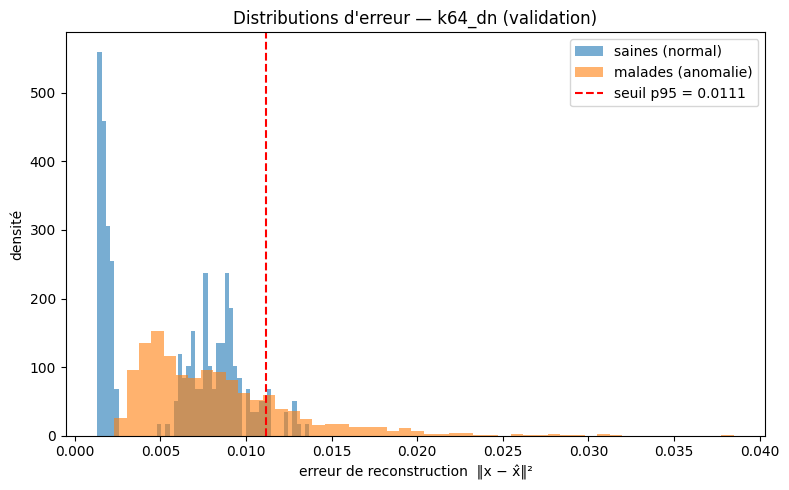

In [15]:
# --- Modèle retenu (meilleur AUROC validation) ---
best_name = "k64_dn"
best_ae   = candidates[best_name]

# --- Erreurs sur validation : fixer le seuil = percentile 95 des SAINES ---
err_v, y_v = recon_errors(best_ae, val_eval)
seuil = np.percentile(err_v[y_v == 0], 95)       # seuil fixé sur la val, saines uniquement
print(f"Seuil (p95 saines val) = {seuil:.5f}")

# --- Histogrammes des deux distributions (validation) ---
plt.figure(figsize=(8, 5))
plt.hist(err_v[y_v == 0], bins=50, alpha=0.6, density=True, label="saines (normal)")
plt.hist(err_v[y_v == 1], bins=50, alpha=0.6, density=True, label="malades (anomalie)")
plt.axvline(seuil, color="red", ls="--", label=f"seuil p95 = {seuil:.4f}")
plt.xlabel("erreur de reconstruction  ‖x − x̂‖²"); plt.ylabel("densité")
plt.title(f"Distributions d'erreur — {best_name} (validation)")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "ae_hist_anomaly.png"), dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** Seuil = **0,0111**. Les deux distributions **se chevauchent largement** : les malades sont décalées vers la droite mais restent très superposées aux saines (d'où l'AUROC ~0,65). On est loin du cas d'école du cours (slide 21) où bleu et rouge sont nettement séparés.

**Évaluation unique sur le test.** AUROC (indépendant du seuil) + rappel des maladies et taux de fausses alarmes **au seuil p95**.

In [16]:
# --- Évaluation UNIQUE sur le test ---
err_t, y_t = recon_errors(best_ae, test_eval)

auroc_test = roc_auc_score(y_t, err_t)
pred = (err_t > seuil).astype(int)               # 1 = détecté comme anomalie
rappel = ((pred == 1) & (y_t == 1)).sum() / (y_t == 1).sum()   # maladies détectées
fausses_alarmes = ((pred == 1) & (y_t == 0)).sum() / (y_t == 0).sum()  # saines mal classées

print(f"AUROC (test)              : {auroc_test:.4f}")
print(f"Rappel maladies (test)    : {rappel:.3f}")
print(f"Taux de fausses alarmes   : {fausses_alarmes:.3f}")

AUROC (test)              : 0.6146
Rappel maladies (test)    : 0.206
Taux de fausses alarmes   : 0.063


**Interprétation.**

| métrique (test) | valeur |
|---|---|
| AUROC | 0,615 |
| Rappel maladies | 0,206 |
| Fausses alarmes | 0,063 |

Seules **~21 % des maladies** dépassent le seuil : l'AE reconstruit **trop bien** la majorité des feuilles malades, dont l'erreur reste sous le seuil → non détectées. Le FAR (6,3 %) dépasse un peu les 5 % visés sur val → léger écart val→test, à mentionner honnêtement. Ce rappel faible est le **constat assumé** qui motive la Partie 4 (combiner l'AE avec le signal du classifieur).

## 7. Analyse des échecs

Grâce au `shuffle=False`, on relie chaque erreur du test à sa **vraie maladie** pour voir lesquelles passent sous le radar.

In [17]:
# alignement erreurs <-> classes (même ordre car shuffle=False)
tdf = test_all.reset_index(drop=True).copy()
tdf["err"]      = err_t
tdf["detectee"] = err_t > seuil

# on ne garde que les malades, et on agrège par maladie
dis = tdf[tdf["label"] != HEALTHY_CLASS]
recap = (dis.groupby("label")
            .agg(n=("err", "size"),
                 err_moyenne=("err", "mean"),
                 taux_detection=("detectee", "mean"))
            .sort_values("taux_detection"))
recap.round(4)

,n,err_moyenne,taux_detection
label,,,
Tomato_Bacterial_spot,319,0.0047,0.0094
Tomato__Tomato_mosaic_virus,56,0.0059,0.0179
Tomato_Spider_mites_Two_spotted_spider_mite,251,0.0072,0.0518
Tomato__Target_Spot,211,0.0079,0.1327
Tomato_Leaf_Mold,143,0.0080,0.1469
Tomato__Tomato_YellowLeaf__Curl_Virus,481,0.0091,0.2827
Tomato_Early_blight,150,0.0095,0.3000
Tomato_Late_blight,285,0.0093,0.3509
Tomato_Septoria_leaf_spot,266,0.0103,0.3722


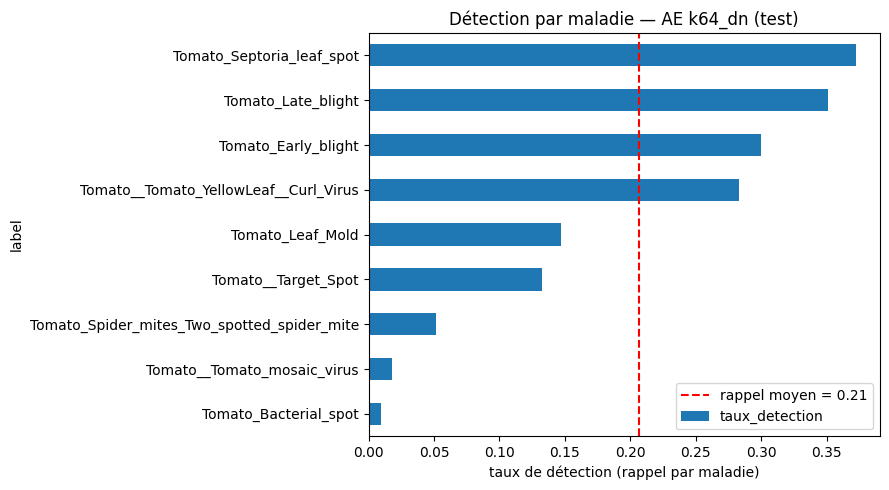

In [18]:
# visualisation : taux de détection par maladie
plt.figure(figsize=(9, 5))
recap["taux_detection"].plot(kind="barh")
plt.axvline(rappel, color="red", ls="--", label=f"rappel moyen = {rappel:.2f}")
plt.xlabel("taux de détection (rappel par maladie)")
plt.title("Détection par maladie — AE k64_dn (test)")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS, "ae_detection_par_classe.png"), dpi=120, bbox_inches="tight")
plt.show()

**Interprétation.** Le taux de détection varie fortement selon la maladie.
- **Bien détectées** : Septoria (0,37), Late_blight (0,35), Early_blight (0,30), YellowLeaf_Curl (0,28) — lésions **étendues/contrastées** ou **déformation globale** de la feuille (jaunissement, recroquevillement) → grosse erreur de reconstruction.
- **Mal détectées** : Bacterial_spot (0,01), mosaic_virus (0,02), Spider_mites (0,05), Target_Spot (0,13), Leaf_Mold (0,15) — symptômes **petits, ponctuels ou subtils**, noyés dans une MSE **moyennée sur toute l'image**.

**Règle qui se dégage** : l'auto-encodeur capte les anomalies **globales**, pas les anomalies **locales fines**. C'est une limite **structurelle** du score « erreur de reconstruction moyenne », et l'argument central en faveur du système hybride (Partie 4).

**Sauvegarde pour la Partie 4.** Le système hybride rechargera **cet** auto-encodeur et **ce** seuil — on les persiste sur Drive.

In [19]:
# --- Sauvegarde pour la Partie 4 (le système hybride réutilise CET AE) ---
torch.save(best_ae.state_dict(), os.path.join(MODELS, "ae_best.pt"))
with open(os.path.join(MODELS, "ae_config.json"), "w") as f:
    json.dump({"best_name": best_name, "k": 64, "denoising": True,
               "noise_std": 0.1, "seuil_p95": float(seuil),
               "auroc_test": float(auroc_test)}, f)
print("AE retenu + seuil sauvegardes :", os.path.join(MODELS, "ae_best.pt"))

AE retenu + seuil sauvegardes : /content/drive/MyDrive/Project_clean/models/ae_best.pt


## 8. Conclusion de la Partie 3

**Ce qui a été fait** (les 5 étapes de l'annexe) :
1. Auto-encodeur convolutif 64×64 (encodeur Conv / décodeur ConvTranspose), entraîné sur feuilles **saines uniquement**, perte MSE.
2. Étude de **k ∈ {16, 64, 256}** : la MSE de reconstruction décroît avec k (0,0077 → 0,0047), reconstructions de plus en plus nettes.
3. Variante **débruiteuse** (bruit 0,1) : filtrage efficace du bruit, et meilleur détecteur que l'AE simple.
4. **Détection d'anomalies** : seuil = p95 des saines (val) = 0,0111 ; sur le test **AUROC 0,615 · rappel 0,206 · fausses alarmes 0,063**.
5. **Analyse des échecs** : les maladies à symptômes globaux sont détectées, celles à taches petites/subtiles sont manquées.

**Enseignements majeurs.**
- *Reconstruction trop bonne* : augmenter k améliore la reconstruction mais **dégrade** la détection → sélection par **AUROC**, pas par MSE.
- Un AE seul, jugé sur l'erreur **globale**, est un **détecteur faible** pour des anomalies **locales** (petites lésions) → justifie le **système hybride** de la Partie 4 (erreur AE + probabilité softmax du classifieur).

**Livrables produits** (Drive `Project_clean`) : `ae_best.pt`, `ae_config.json` (seuil), et les figures `ae_reconstructions_k.png`, `ae_denoising.png`, `ae_hist_anomaly.png`, `ae_detection_par_classe.png`.